In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# Import Libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Dataset Paths
train_path = '/content/drive/MyDrive/Colab Notebooks/DL_Assignment_dataset/Brain Tumor/Training'
test_path = '/content/drive/MyDrive/Colab Notebooks/DL_Assignment_dataset/Brain Tumor/Testing'


In [4]:
# Data Generators (smaller image size + augmentations)
IMG_SIZE = (150, 150)
BATCH_SIZE = 16

train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
).flow_from_directory(train_path, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical')

test_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
).flow_from_directory(test_path, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)



Found 2870 images belonging to 4 classes.
Found 394 images belonging to 4 classes.


In [5]:
# Build Model
base = VGG19(weights='imagenet', include_top=False, input_shape=(150,150,3))
base.trainable = False  # freeze base layers

x = GlobalAveragePooling2D()(base.output)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
out = Dense(train_gen.num_classes, activation='softmax')(x)
model = Model(inputs=base.input, outputs=out)

model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 20,156,740 (76.89 MB)

 Trainable params: 132,356 (517.02 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [6]:

# Callbacks
lr_reduce = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)


In [7]:
# Train Model (5 epochs)
print("\n--- Training Top Layers ---")
history1 = model.fit(train_gen, epochs=5, validation_data=test_gen, callbacks=[lr_reduce, early_stop])



--- Training Top Layers ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
180/180 ━━━━━━━━━━━━━━━━━━━━ 709s 4s/step - accuracy: 0.3405 - loss: 4.4899 - val_accuracy: 0.4670 - val_loss: 2.4053 - learning_rate: 1.0000e-04
Epoch 2/5
180/180 ━━━━━━━━━━━━━━━━━━━━ 32s 175ms/step - accuracy: 0.5000 - loss: 2.3032 - val_accuracy: 0.5127 - val_loss: 2.3404 - learning_rate: 1.0000e-04
Epoch 3/5
180/180 ━━━━━━━━━━━━━━━━━━━━ 31s 174ms/step - accuracy: 0.5839 - loss: 1.6338 - val_accuracy: 0.5279 - val_loss: 2.0512 - learning_rate: 1.0000e-04
Epoch 4/5
180/180 ━━━━━━━━━━━━━━━━━━━━ 32s 178ms/step - accuracy: 0.6278 - loss: 1.2592 - val_accuracy: 0.5355 - val_loss: 1.9775 - learning_rate: 1.0000e-04
Epoch 5/5
180/180 ━━━━━━━━━━━━━━━━━━━━ 31s 173ms/step - accuracy: 0.6402 - loss: 1.1085 - val_accuracy: 0.5761 - val_loss: 1.7817 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 5.


In [8]:
# Fine-tune some layers of VGG19 (10 epochs)
print("\n--- Fine-tuning Model ---")
base.trainable = True
for layer in base.layers[:-5]:
    layer.trainable = False

model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
history2 = model.fit(train_gen, epochs=10, validation_data=test_gen, callbacks=[lr_reduce, early_stop])



--- Fine-tuning Model ---
Epoch 1/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 42s 203ms/step - accuracy: 0.6938 - loss: 0.8796 - val_accuracy: 0.6269 - val_loss: 1.3666 - learning_rate: 1.0000e-05
Epoch 2/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 33s 185ms/step - accuracy: 0.7813 - loss: 0.5877 - val_accuracy: 0.6320 - val_loss: 1.5152 - learning_rate: 1.0000e-05
Epoch 3/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 32s 179ms/step - accuracy: 0.8248 - loss: 0.4598 - val_accuracy: 0.6701 - val_loss: 1.5396 - learning_rate: 1.0000e-05
Epoch 4/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.8557 - loss: 0.3622
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
180/180 ━━━━━━━━━━━━━━━━━━━━ 33s 184ms/step - accuracy: 0.8557 - loss: 0.3622 - val_accuracy: 0.6980 - val_loss: 1.5107 - learning_rate: 1.0000e-05
Epoch 5/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 32s 179ms/step - accuracy: 0.8774 - loss: 0.3285 - val_accuracy: 0.7284 - val_loss: 1.5509 - learning_rate: 5.0000e-06
Epoch 6/10
180/180 ━━━━━━

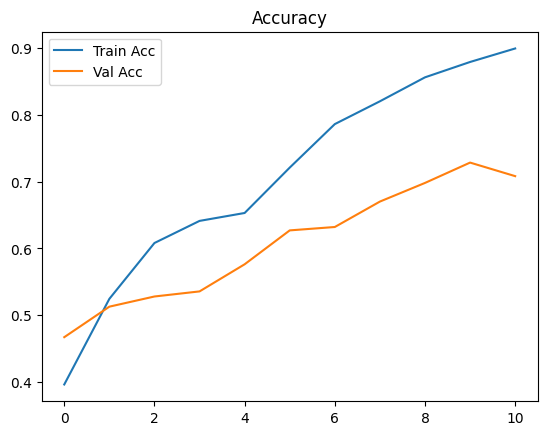

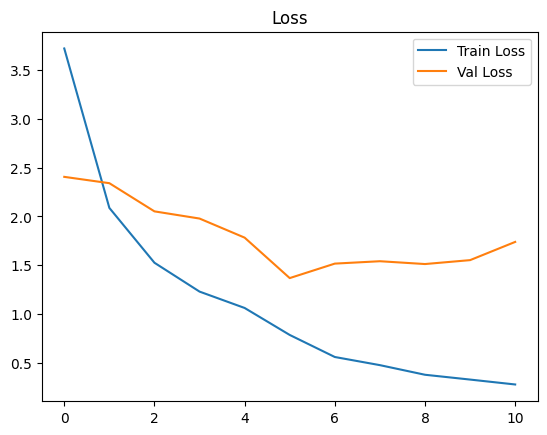

In [9]:
# Accuracy & Loss Graphs
def plot_graphs(h1, h2):
    acc = h1.history['accuracy'] + h2.history['accuracy']
    val_acc = h1.history['val_accuracy'] + h2.history['val_accuracy']
    plt.plot(acc, label='Train Acc')
    plt.plot(val_acc, label='Val Acc')
    plt.legend(); plt.title('Accuracy'); plt.show()

    loss = h1.history['loss'] + h2.history['loss']
    val_loss = h1.history['val_loss'] + h2.history['val_loss']
    plt.plot(loss, label='Train Loss')
    plt.plot(val_loss, label='Val Loss')
    plt.legend(); plt.title('Loss'); plt.show()

plot_graphs(history1, history2)

25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step

Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       0.65      0.34      0.45       100
meningioma_tumor       0.60      0.67      0.63       115
        no_tumor       0.60      0.85      0.70       105
 pituitary_tumor       0.71      0.64      0.67        74

        accuracy                           0.63       394
       macro avg       0.64      0.62      0.61       394
    weighted avg       0.64      0.63      0.61       394



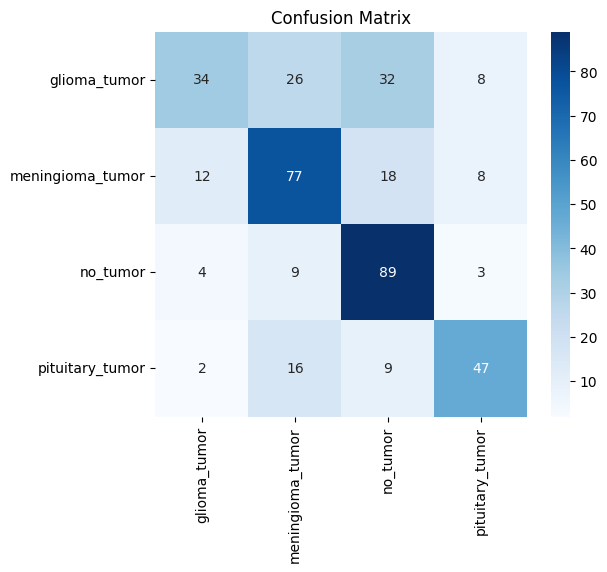

In [10]:
# Evaluation
pred = model.predict(test_gen)
y_pred = np.argmax(pred, axis=1)
y_true = test_gen.classes

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=list(test_gen.class_indices.keys())))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_gen.class_indices.keys(),
            yticklabels=test_gen.class_indices.keys())
plt.title('Confusion Matrix')
plt.show()